# 01 — CNNs From Scratch: Convolution, Stride, Padding, Pooling

**Overview:** implement 2D convolution, stride, padding, and max pooling from scratch on a
small synthetic "image," and use a hand-designed kernel to detect a specific pattern.

**Required libraries:** `numpy`, `matplotlib`.

Connects to: `15_deep_learning` (weighted sums + activations, now spatially local). Leads to:
`02_rnn_lstm_gru_concept.ipynb`.

### Abbreviations used in this notebook

| Term | Full form | What it is |
|---|---|---|
| **CNN** | Convolutional Neural Network | Network using sliding-filter convolutions; strong on images. |
| **RNN** | Recurrent Neural Network | Processes sequences step by step, carrying a hidden state. |
| **ReLU** | Rectified Linear Unit | Activation max(0, x). |

## 0. Environment

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)


## 1. 2D convolution from scratch

**Equation:** `output[i,j] = sum over the kernel window of (input patch * kernel)`

💡 **Intuition:** the same small kernel is reused (parameter sharing) at every position --
this is why CNNs use far fewer parameters than a fully-connected layer would for the same
input size.

In [2]:
def conv2d(image, kernel, stride=1, padding=0):
    if padding > 0:
        image = np.pad(image, padding, mode="constant")

    H, W = image.shape
    kH, kW = kernel.shape
    out_H = (H - kH) // stride + 1
    out_W = (W - kW) // stride + 1
    output = np.zeros((out_H, out_W))

    for i in range(out_H):
        for j in range(out_W):
            row_start, col_start = i * stride, j * stride
            patch = image[row_start:row_start + kH, col_start:col_start + kW]
            output[i, j] = np.sum(patch * kernel)
    return output

# Output shape formula check: (H - K + 1) for stride=1, padding=0.
toy_image = rng.normal(size=(8, 8))
toy_kernel = rng.normal(size=(3, 3))
result = conv2d(toy_image, toy_kernel)
print("input shape:", toy_image.shape, "kernel shape:", toy_kernel.shape, "-> output shape:", result.shape)
assert result.shape == (8 - 3 + 1, 8 - 3 + 1)


input shape: (8, 8) kernel shape: (3, 3) -> output shape: (6, 6)


## 2. A hand-designed kernel that detects vertical edges

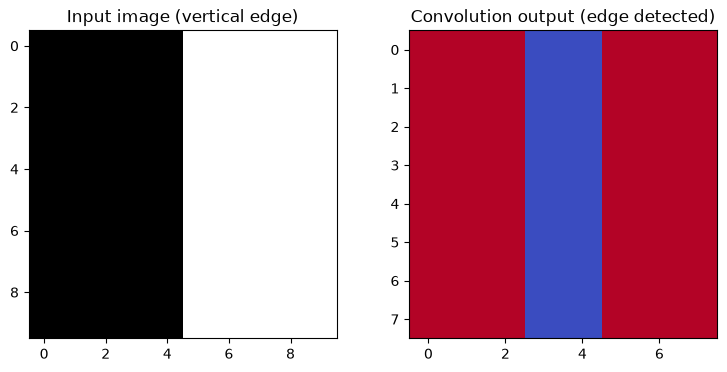

column with the strongest edge response: 3 (should be near the true edge)


In [3]:
# A simple vertical-edge detector: strongly positive on the left, strongly negative on the right.
vertical_edge_kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1],
])

# A synthetic "image" with one clean vertical edge in the middle.
edge_image = np.zeros((10, 10))
edge_image[:, 5:] = 1.0   # right half is bright, left half is dark

edge_response = conv2d(edge_image, vertical_edge_kernel)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(edge_image, cmap="gray"); axes[0].set_title("Input image (vertical edge)")
axes[1].imshow(edge_response, cmap="coolwarm"); axes[1].set_title("Convolution output (edge detected)")
plt.show()

# The strongest response should be concentrated near the true edge column (index 5 in the original).
peak_col = np.argmax(np.abs(edge_response).sum(axis=0))
print("column with the strongest edge response:", peak_col, "(should be near the true edge)")
assert abs(peak_col - edge_response.shape[1] // 2) <= 1


## 3. Stride and padding, and their effect on output shape

⚠️ **Common Mistake:** forgetting that stride and padding change output size, leading to
shape-mismatch errors several layers deeper in a real CNN.

In [4]:
configs = [
    ("stride=1, padding=0", 1, 0),
    ("stride=2, padding=0", 2, 0),
    ("stride=1, padding=1", 1, 1),
    ("stride=2, padding=1", 2, 1),
]

print(f"input: {toy_image.shape}, kernel: {toy_kernel.shape}\n")
for name, stride, padding in configs:
    out = conv2d(toy_image, toy_kernel, stride=stride, padding=padding)
    H, W = toy_image.shape
    kH, kW = toy_kernel.shape
    expected_out_dim = lambda dim, k: (dim + 2 * padding - k) // stride + 1
    expected_shape = (expected_out_dim(H, kH), expected_out_dim(W, kW))
    print(f"{name:20s} -> output shape {out.shape}  (formula predicts {expected_shape})")
    assert out.shape == expected_shape


input: (8, 8), kernel: (3, 3)

stride=1, padding=0  -> output shape (6, 6)  (formula predicts (6, 6))
stride=2, padding=0  -> output shape (3, 3)  (formula predicts (3, 3))
stride=1, padding=1  -> output shape (8, 8)  (formula predicts (8, 8))
stride=2, padding=1  -> output shape (4, 4)  (formula predicts (4, 4))


## 4. Max pooling from scratch

💡 **Intuition:** pooling downsamples and adds a small amount of translation invariance --
a feature detected slightly off-position still triggers a similar pooled output.

In [5]:
def max_pool2d(feature_map, pool_size=2, stride=2):
    H, W = feature_map.shape
    out_H = (H - pool_size) // stride + 1
    out_W = (W - pool_size) // stride + 1
    output = np.zeros((out_H, out_W))
    for i in range(out_H):
        for j in range(out_W):
            row_start, col_start = i * stride, j * stride
            patch = feature_map[row_start:row_start + pool_size, col_start:col_start + pool_size]
            output[i, j] = patch.max()
    return output

feature_map = np.array([
    [1, 3, 2, 4],
    [5, 6, 1, 2],
    [1, 2, 7, 8],
    [3, 4, 5, 9],
])
pooled = max_pool2d(feature_map, pool_size=2, stride=2)
print("feature map:\n", feature_map)
print("\nmax-pooled (2x2, stride 2):\n", pooled)

assert pooled.shape == (2, 2)
assert pooled[0, 0] == 6   # max of top-left 2x2 block [[1,3],[5,6]]
assert pooled[1, 1] == 9   # max of bottom-right 2x2 block [[7,8],[5,9]]


feature map:
 [[1 3 2 4]
 [5 6 1 2]
 [1 2 7 8]
 [3 4 5 9]]

max-pooled (2x2, stride 2):
 [[6. 4.]
 [4. 9.]]


## 5. Connection to what's next

A real CNN stacks many `conv -> activation -> pool` blocks, each layer detecting increasingly
abstract patterns (edges → textures → shapes → objects). `02_rnn_lstm_gru_concept.ipynb`
switches from spatial locality (CNNs) to sequential/temporal locality (RNNs).

## 6. Interview questions
1. Why does parameter sharing in convolution reduce the number of learnable parameters compared to a fully-connected layer?
2. How does the formula `(H + 2*padding - K) / stride + 1` explain why "same" padding keeps output size equal to input size when stride=1?
3. What does max pooling add besides downsampling?
4. Why might you choose a larger stride instead of pooling to downsample?
5. What would happen to a CNN's edge-detection kernel's response if the edge in the image were blurred instead of sharp?

## 7. Exercises
1. Design a horizontal-edge-detection kernel and verify it responds strongly to a horizontal edge but weakly to the vertical edge from this notebook.
2. Implement average pooling and compare its output to max pooling on the same feature map.
3. Chain two convolutions (with a ReLU activation between them) and verify the final output shape using the stride/padding formula twice.

## 8. Summary

✅ Convolution detects local patterns with a shared, learnable kernel; stride and padding
control output size; pooling downsamples and adds translation invariance. Next:
`02_rnn_lstm_gru_concept.ipynb`.